In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Load and verify the dataset

In [2]:
import json

data_path = '/content/drive/MyDrive/en-US.jsonl'

with open(data_path, encoding="utf-8") as f:
    records = [json.loads(line) for line in f if line.strip()]

train_data = [r for r in records if r["partition"] == "train"]
dev_data   = [r for r in records if r["partition"] == "dev"]
test_data  = [r for r in records if r["partition"] == "test"]

print(f"Total examples:      {len(records)}")
print(f"Training examples:   {len(train_data)}")
print(f"Validation examples: {len(dev_data)}")
print(f"Test examples:       {len(test_data)}")

assert len(records) == 16521
assert len(train_data) == 11514
assert len(dev_data) == 2033
assert len(test_data) == 2974
print("All split sizes verified.")

print("\nExample record:", train_data[0])

Total examples:      16521
Training examples:   11514
Validation examples: 2033
Test examples:       2974
All split sizes verified.

Example record: {'id': '1', 'locale': 'en-US', 'partition': 'train', 'scenario': 'alarm', 'intent': 'alarm_set', 'utt': 'wake me up at nine am on friday', 'annot_utt': 'wake me up at [time : nine am] on [date : friday]', 'worker_id': '1'}


Preprocessing of data and setup

In [3]:
import json, os, re, time, random, tarfile, urllib.request
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cuda


In [4]:
SLOT_RE = re.compile(r"\[\s*([^\]:]+?)\s*:\s*([^\]]*?)\s*\]")

def parse_annot(annot_utt):
    tokens, tags, pos = [], [], 0
    for m in SLOT_RE.finditer(annot_utt):
        for w in annot_utt[pos:m.start()].split():
            tokens.append(w); tags.append("O")
        slot_type = m.group(1).strip()
        for i, w in enumerate(m.group(2).split()):
            tokens.append(w); tags.append(("B-" if i == 0 else "I-") + slot_type)
        pos = m.end()
    for w in annot_utt[pos:].split():
        tokens.append(w); tags.append("O")
    return tokens, tags

def tags_to_spans(tokens, tags):
    """BIO tags -> set of (slot_type, span_text)."""
    spans, cur_type, cur_words = set(), None, []
    for tok, tag in zip(tokens, tags):
        if tag.startswith("B-") or (tag.startswith("I-") and tag[2:] != cur_type):
            if cur_type:
                spans.add((cur_type, " ".join(cur_words)))
            cur_type, cur_words = tag[2:], [tok]
        elif tag.startswith("I-"):
            cur_words.append(tok)
        else:
            if cur_type:
                spans.add((cur_type, " ".join(cur_words)))
            cur_type, cur_words = None, []
    if cur_type:
        spans.add((cur_type, " ".join(cur_words)))
    return spans

def preprocess(records):
    out = []
    for r in records:
        tokens, tags = parse_annot(r["annot_utt"])
        assert tokens == r["utt"].split(), f"Token mismatch in id {r['id']}"
        out.append({"id": r["id"], "tokens": tokens, "slot_tags": tags,
                    "intent": r["intent"], "gold_spans": tags_to_spans(tokens, tags)})
    return out

train_proc, dev_proc, test_proc = preprocess(train_data), preprocess(dev_data), preprocess(test_data)

# Vocab and label maps are built from the training split only
PAD, UNK = "<pad>", "<unk>"
word_counts = Counter(t.lower() for ex in train_proc for t in ex["tokens"])
word2id = {PAD: 0, UNK: 1}
for w, _ in word_counts.most_common():
    word2id[w] = len(word2id)

intent2id = {it: i for i, it in enumerate(sorted({ex["intent"] for ex in train_proc}))}
id2intent = {i: it for it, i in intent2id.items()}

# B- and I- for every slot type (I-transport_type only appears in test)
slot_types = sorted({t[2:] for ex in train_proc for t in ex["slot_tags"] if t != "O"})
slot2id = {"O": 0}
for st in slot_types:
    slot2id["B-" + st] = len(slot2id)
    slot2id["I-" + st] = len(slot2id)
id2slot = {i: s for s, i in slot2id.items()}

print(f"Vocab: {len(word2id)} | Intents: {len(intent2id)} | "
      f"Slot types: {len(slot_types)} | BIO tags: {len(slot2id)}")
assert len(intent2id) == 60 and len(slot_types) == 55

def encode(ex):
    return {"input_ids": [word2id.get(t.lower(), word2id[UNK]) for t in ex["tokens"]],
            "slot_ids": [slot2id[t] for t in ex["slot_tags"]],
            "intent_id": intent2id[ex["intent"]]}

SLOT_PAD_ID = -100  # ignored by CrossEntropyLoss

class MassiveDataset(Dataset):
    def __init__(self, proc):
        self.data = [encode(ex) for ex in proc]
    def __len__(self):
        return len(self.data)
    def __getitem__(self, idx):
        return self.data[idx]

def collate_fn(batch):
    return {
        "input_ids": pad_sequence([torch.tensor(b["input_ids"]) for b in batch],
                                  batch_first=True, padding_value=word2id[PAD]),
        "slot_ids": pad_sequence([torch.tensor(b["slot_ids"]) for b in batch],
                                 batch_first=True, padding_value=SLOT_PAD_ID),
        "lengths": torch.tensor([len(b["input_ids"]) for b in batch]),
        "intent_id": torch.tensor([b["intent_id"] for b in batch]),
    }

train_ds, dev_ds, test_ds = MassiveDataset(train_proc), MassiveDataset(dev_proc), MassiveDataset(test_proc)
print("Example:", train_proc[0]["tokens"], train_proc[0]["slot_tags"], train_proc[0]["intent"])



Vocab: 5304 | Intents: 60 | Slot types: 55 | BIO tags: 111
Example: ['wake', 'me', 'up', 'at', 'nine', 'am', 'on', 'friday'] ['O', 'O', 'O', 'O', 'B-time', 'I-time', 'O', 'B-date'] alarm_set


Shared Evaluation Functions

In [5]:
def intent_accuracy(pred_intents, gold_intents):
    correct = sum(p == g for p, g in zip(pred_intents, gold_intents))
    return 100.0 * correct / len(gold_intents)

def slot_micro_f1(pred_span_sets, gold_span_sets):
    tp = fp = fn = 0
    for pred, gold in zip(pred_span_sets, gold_span_sets):
        tp += len(pred & gold)
        fp += len(pred - gold)
        fn += len(gold - pred)
    denom = 2 * tp + fp + fn
    return 100.0 * 2 * tp / denom if denom > 0 else 0.0

## Stage 1 (basic version): logistic regression intent classifier + linear-chain CRF slot tagger

A deliberately simple Stage-1 system. Both models are linear, start from zero weights, and are trained on the GPU using only the official training split. No word vectors or pretrained models are used.

- **Task 1, intent:** multinomial logistic regression over a binary bag of lower-cased unigrams and bigrams. It is trained full-batch with Adam on cross-entropy plus an L2 penalty.
- **Task 2, slots:** a linear-chain CRF over the BIO tags. Each token's features are the current word, the previous word and the next word. It is trained on the CRF negative log-likelihood plus an L2 penalty and decoded with Viterbi.
- **Basic tuning:** only the L2 strength is tuned for each model, plus the epoch for the CRF. Selection uses the validation split, with intent accuracy for the classifier and slot micro F1 for the tagger. The test split is evaluated once at the end.
- **Output:** every utterance gets an intent label and a set of (slot type, slot span) pairs. Both are scored with the shared evaluation functions above.

**Run order in a fresh Colab session:** use a GPU runtime. Run the cells for mounting, data loading, setup, preprocessing and shared evaluation functions, then the cells below in order. The CNN/BiLSTM Stage-1 cells and the Stage-2 cells are not needed. If the Stage-2 cells have already run, the final table also lists the Stage-2 system for comparison.

Task 1: logistic regression intent classifier, tuned on validation intent accuracy

In [6]:
# Basic Stage 1, Task 1: logistic regression intent classifier over a bag of unigrams and bigrams
assert device.type == "cuda", "Use a GPU runtime: Runtime > Change runtime type > GPU"
BASIC_DIR = "/content/drive/MyDrive/SC4002"
os.makedirs(BASIC_DIR, exist_ok=True)

def l2_penalty(model):
    """Sum of squared weights of every parameter (plain L2 regularisation)."""
    return sum((p ** 2).sum() for p in model.parameters())

def ngram_features(tokens):
    """Binary bag of lower-cased unigrams and bigrams; <s> and </s> mark the utterance boundaries."""
    words = [t.lower() for t in tokens]
    padded = ["<s>"] + words + ["</s>"]
    return set(words) | {a + " " + b for a, b in zip(padded, padded[1:])}

# Feature vocabulary from the training split only; n-grams never seen in training are ignored
feat2id = {}
for ex in train_proc:
    for f in sorted(ngram_features(ex["tokens"])):
        feat2id.setdefault(f, len(feat2id))

def bag_tensors(proc):
    """Flat feature ids and offsets (the input format of nn.EmbeddingBag) plus intent labels."""
    ids, offsets = [], []
    for ex in proc:
        offsets.append(len(ids))
        ids.extend(feat2id[f] for f in ngram_features(ex["tokens"]) if f in feat2id)
    labels = torch.tensor([intent2id[ex["intent"]] for ex in proc], device=device)
    return torch.tensor(ids, device=device), torch.tensor(offsets, device=device), labels

X_tr, O_tr, y_tr = bag_tensors(train_proc)
X_dev, O_dev, y_dev = bag_tensors(dev_proc)
X_test, O_test, y_test = bag_tensors(test_proc)


class BoWLogReg(nn.Module):
    """Multinomial logistic regression: logits = W x + b, where x is the binary n-gram bag."""
    def __init__(self, n_feats, n_classes):
        super().__init__()
        self.W = nn.EmbeddingBag(n_feats, n_classes, mode="sum")   # sum of W rows = W x for a sparse x
        nn.init.zeros_(self.W.weight)
        self.b = nn.Parameter(torch.zeros(n_classes))

    def forward(self, ids, offsets):
        return self.W(ids, offsets) + self.b


LOGREG_CONFIG = {"l2_grid": [0.0, 1e-5, 1e-4, 1e-3], "lr": 0.05, "steps": 300}

def train_logreg(l2, cfg=LOGREG_CONFIG):
    """Full-batch Adam on cross-entropy + l2 * ||w||^2 (the problem is convex, so it simply converges)."""
    set_seed()
    model = BoWLogReg(len(feat2id), len(intent2id)).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    for _ in range(cfg["steps"]):
        loss = F.cross_entropy(model(X_tr, O_tr), y_tr) + l2 * l2_penalty(model)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return model, loss.item()

@torch.no_grad()
def logreg_predict(model, ids, offsets):
    model.eval()
    return [id2intent[i] for i in model(ids, offsets).argmax(-1).tolist()]

# Basic tuning: pick the L2 strength with the highest validation intent accuracy
dev_gold_intents = [ex["intent"] for ex in dev_proc]
logreg_runs = {}
for l2 in LOGREG_CONFIG["l2_grid"]:
    t0 = time.time()
    m, train_loss = train_logreg(l2)
    acc = intent_accuracy(logreg_predict(m, X_dev, O_dev), dev_gold_intents)
    logreg_runs[l2] = {"model": m, "val_intent_acc": acc}
    print(f"L2 {l2:<7g} | final train loss {train_loss:.4f} | val intent acc {acc:.2f} | {time.time() - t0:.1f}s")

best_logreg_l2 = max(logreg_runs, key=lambda k: logreg_runs[k]["val_intent_acc"])
logreg_model = logreg_runs[best_logreg_l2]["model"]
print(f"\nFeatures: {len(feat2id):,} n-grams | params: {sum(p.numel() for p in logreg_model.parameters()):,}")
print(f"Selected L2 = {best_logreg_l2:g} | val intent acc {logreg_runs[best_logreg_l2]['val_intent_acc']:.2f}")

L2 0       | final train loss 0.0012 | val intent acc 82.14 | 5.8s
L2 1e-05   | final train loss 0.1678 | val intent acc 84.41 | 0.6s
L2 0.0001  | final train loss 0.6892 | val intent acc 83.82 | 0.6s
L2 0.001   | final train loss 1.9106 | val intent acc 74.67 | 0.6s

Features: 32,785 n-grams | params: 1,967,160
Selected L2 = 1e-05 | val intent acc 84.41


Task 2: linear-chain CRF slot tagger, tuned on validation slot micro F1

In [7]:
# Basic Stage 1, Task 2: linear-chain CRF slot tagger over BIO tags
# Features of token t: the current word, the previous word and the next word (one weight per word and tag).
BOS_ID, EOS_ID = len(word2id), len(word2id) + 1     # extra word ids for "before the start" / "after the end"
N_WORDS, N_TAGS = len(word2id) + 2, len(slot2id)

def crf_encode(ex):
    cur = [word2id.get(t.lower(), word2id[UNK]) for t in ex["tokens"]]
    return {"cur": cur, "prev": [BOS_ID] + cur[:-1], "next": cur[1:] + [EOS_ID],
            "tags": [slot2id[t] for t in ex["slot_tags"]]}

def crf_collate(batch):
    def pad(key):
        return pad_sequence([torch.tensor(b[key]) for b in batch], batch_first=True, padding_value=0)
    lengths = torch.tensor([len(b["cur"]) for b in batch])
    mask = torch.arange(lengths.max())[None, :] < lengths[:, None]
    return {"cur": pad("cur"), "prev": pad("prev"), "next": pad("next"), "tags": pad("tags"),
            "lengths": lengths, "mask": mask}

def crf_to_device(batch):
    return {k: v.to(device) for k, v in batch.items()}

crf_train_data = [crf_encode(ex) for ex in train_proc]
crf_dev_loader = DataLoader([crf_encode(ex) for ex in dev_proc], batch_size=256, collate_fn=crf_collate)
crf_test_loader = DataLoader([crf_encode(ex) for ex in test_proc], batch_size=256, collate_fn=crf_collate)


class LinearCRF(nn.Module):
    """score(x, y) = sum_t [emit(t, y_t) + trans(y_{t-1}, y_t)] + start(y_1) + end(y_T), with
    emit(t, y) = w_cur[x_t, y] + w_prev[x_{t-1}, y] + w_next[x_{t+1}, y] + b[y]."""
    def __init__(self, n_words, n_tags):
        super().__init__()
        self.w_cur = nn.Embedding(n_words, n_tags, padding_idx=0)
        self.w_prev = nn.Embedding(n_words, n_tags, padding_idx=0)
        self.w_next = nn.Embedding(n_words, n_tags, padding_idx=0)
        for table in (self.w_cur, self.w_prev, self.w_next):
            nn.init.zeros_(table.weight)
        self.bias = nn.Parameter(torch.zeros(n_tags))
        self.trans = nn.Parameter(torch.zeros(n_tags, n_tags))      # trans[i, j]: tag i followed by tag j
        self.start = nn.Parameter(torch.zeros(n_tags))
        self.end = nn.Parameter(torch.zeros(n_tags))

    def emissions(self, b):
        return self.w_cur(b["cur"]) + self.w_prev(b["prev"]) + self.w_next(b["next"]) + self.bias  # (B, T, N)

    def nll(self, b):
        """Mean negative log-likelihood of the gold tag sequences (forward algorithm)."""
        em, tags, mask = self.emissions(b), b["tags"], b["mask"]
        maskf = mask.float()
        gold = self.start[tags[:, 0]] + (em.gather(2, tags.unsqueeze(2)).squeeze(2) * maskf).sum(1)
        gold = gold + (self.trans[tags[:, :-1], tags[:, 1:]] * maskf[:, 1:]).sum(1)
        gold = gold + self.end[tags.gather(1, (b["lengths"] - 1).unsqueeze(1)).squeeze(1)]
        alpha = self.start + em[:, 0]                                  # (B, N)
        for t in range(1, em.size(1)):
            nxt = torch.logsumexp(alpha.unsqueeze(2) + self.trans, dim=1) + em[:, t]
            alpha = torch.where(mask[:, t:t + 1], nxt, alpha)
        return (torch.logsumexp(alpha + self.end, dim=1) - gold).mean()

    @torch.no_grad()
    def decode(self, b):
        """Viterbi: highest-scoring tag sequence (B, T); padded positions repeat the last real tag."""
        em, mask = self.emissions(b), b["mask"]
        B, T, N = em.shape
        score = self.start + em[:, 0]
        keep = torch.arange(N, device=em.device).expand(B, N)
        backptrs = []
        for t in range(1, T):
            best, idx = (score.unsqueeze(2) + self.trans).max(dim=1)
            m = mask[:, t:t + 1]
            score = torch.where(m, best + em[:, t], score)
            backptrs.append(torch.where(m, idx, keep))
        tag = (score + self.end).argmax(dim=1)
        path = [tag]
        for bp in reversed(backptrs):
            tag = bp.gather(1, tag.unsqueeze(1)).squeeze(1)
            path.append(tag)
        return torch.stack(path[::-1], dim=1)


def crf_predict(model, loader, proc):
    """Predicted (slot type, span) sets in dataset order."""
    model.eval()
    spans, idx = [], 0
    for b in loader:
        b = crf_to_device(b)
        for row, L in zip(model.decode(b).tolist(), b["lengths"].tolist()):
            spans.append(tags_to_spans(proc[idx]["tokens"], [id2slot[t] for t in row[:L]]))
            idx += 1
    return spans


CRF_CONFIG = {"l2_grid": [0.0, 1e-5, 1e-4], "lr": 0.05, "batch_size": 64, "epochs": 15}

# Basic tuning: for each L2 strength train for a fixed number of epochs; keep the epoch and L2
# with the highest validation slot micro F1
dev_gold_spans = [ex["gold_spans"] for ex in dev_proc]
crf_history = {}
crf_best = {"val_slot_f1": -1.0}
start = time.time()
for l2 in CRF_CONFIG["l2_grid"]:
    set_seed()
    model_crf = LinearCRF(N_WORDS, N_TAGS).to(device)
    optimizer = torch.optim.Adam(model_crf.parameters(), lr=CRF_CONFIG["lr"])
    loader = DataLoader(crf_train_data, batch_size=CRF_CONFIG["batch_size"], shuffle=True,
                        collate_fn=crf_collate, generator=torch.Generator().manual_seed(SEED))
    crf_history[l2] = []
    for epoch in range(1, CRF_CONFIG["epochs"] + 1):
        model_crf.train()
        total, n = 0.0, 0
        for b in loader:
            b = crf_to_device(b)
            loss = model_crf.nll(b) + l2 * l2_penalty(model_crf)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item(); n += 1
        f1 = slot_micro_f1(crf_predict(model_crf, crf_dev_loader, dev_proc), dev_gold_spans)
        crf_history[l2].append({"epoch": epoch, "train_loss": total / n, "val_slot_f1": f1})
        if f1 > crf_best["val_slot_f1"]:
            crf_best = {"l2": l2, "epoch": epoch, "val_slot_f1": f1,
                        "state": {k: v.detach().clone() for k, v in model_crf.state_dict().items()}}
    best_ep = max(crf_history[l2], key=lambda h: h["val_slot_f1"])
    print(f"L2 {l2:<7g} | best epoch {best_ep['epoch']:2d} | val slot F1 {best_ep['val_slot_f1']:.2f} | "
          f"final train loss {crf_history[l2][-1]['train_loss']:.4f}")

print(f"\nCRF tuning time: {time.time() - start:.1f}s | params: {sum(p.numel() for p in model_crf.parameters()):,}")
print(f"Selected L2 = {crf_best['l2']:g}, epoch {crf_best['epoch']} | val slot F1 {crf_best['val_slot_f1']:.2f}")

L2 0       | best epoch  3 | val slot F1 77.38 | final train loss 0.1920
L2 1e-05   | best epoch  9 | val slot F1 77.40 | final train loss 1.1353
L2 0.0001  | best epoch 15 | val slot F1 69.73 | final train loss 3.0134

CRF tuning time: 113.1s | params: 1,779,552
Selected L2 = 1e-05, epoch 9 | val slot F1 77.40


Tuning curves

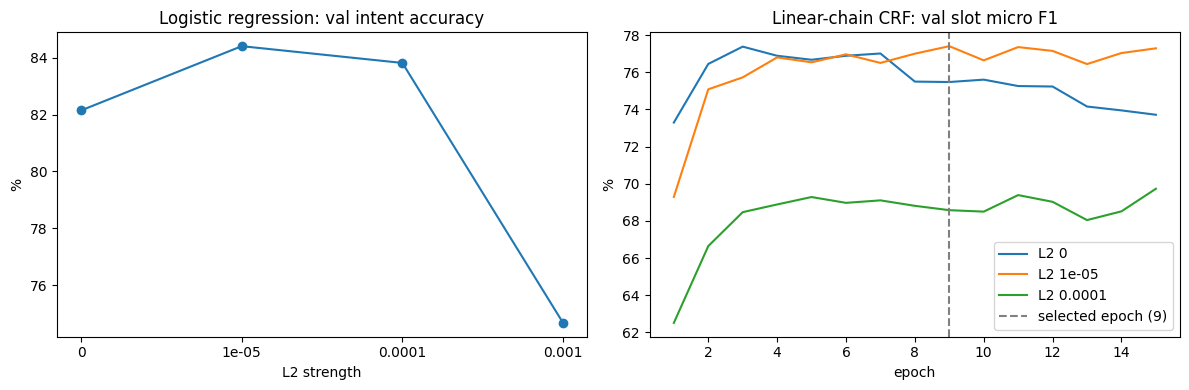

In [8]:
# Tuning curves: validation intent accuracy per L2 strength, and CRF validation slot F1 per epoch
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
grid = LOGREG_CONFIG["l2_grid"]
axes[0].plot(range(len(grid)), [logreg_runs[l2]["val_intent_acc"] for l2 in grid], marker="o")
axes[0].set_xticks(range(len(grid)), [f"{l2:g}" for l2 in grid])
axes[0].set_xlabel("L2 strength"); axes[0].set_ylabel("%"); axes[0].set_title("Logistic regression: val intent accuracy")
for l2, hist in crf_history.items():
    axes[1].plot([h["epoch"] for h in hist], [h["val_slot_f1"] for h in hist], label=f"L2 {l2:g}")
axes[1].axvline(crf_best["epoch"], color="gray", linestyle="--", label=f"selected epoch ({crf_best['epoch']})")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("%"); axes[1].set_title("Linear-chain CRF: val slot micro F1")
axes[1].legend()
plt.tight_layout(); plt.show()

Final evaluation of the basic Stage-1 system on validation and test

In [9]:
# Save the selected models, reload them, and evaluate once on validation and test
BASIC_CKPT = os.path.join(BASIC_DIR, "stage1_basic_best.pt")
torch.save({"logreg_state": logreg_model.state_dict(), "logreg_l2": best_logreg_l2,
            "crf_state": crf_best["state"], "crf_l2": crf_best["l2"], "crf_epoch": crf_best["epoch"],
            "feat2id": feat2id, "word2id": word2id, "intent2id": intent2id, "slot2id": slot2id}, BASIC_CKPT)

ckpt_basic = torch.load(BASIC_CKPT, map_location=device, weights_only=False)
assert ckpt_basic["feat2id"] == feat2id and ckpt_basic["word2id"] == word2id, "Vocabulary differs from checkpoint"
basic_logreg = BoWLogReg(len(feat2id), len(intent2id)).to(device)
basic_logreg.load_state_dict(ckpt_basic["logreg_state"])
basic_crf = LinearCRF(N_WORDS, N_TAGS).to(device)
basic_crf.load_state_dict(ckpt_basic["crf_state"])

def evaluate_basic(proc, ids, offsets, crf_loader):
    """Every utterance gets an intent label and a set of (slot type, slot span) pairs."""
    pred_intents = logreg_predict(basic_logreg, ids, offsets)
    pred_spans = crf_predict(basic_crf, crf_loader, proc)
    acc = intent_accuracy(pred_intents, [ex["intent"] for ex in proc])
    f1 = slot_micro_f1(pred_spans, [ex["gold_spans"] for ex in proc])
    return {"intent_acc": acc, "slot_f1": f1, "combined": (acc + f1) / 2,
            "pred_intents": pred_intents, "pred_spans": pred_spans}

val_basic = evaluate_basic(dev_proc, X_dev, O_dev, crf_dev_loader)
test_basic = evaluate_basic(test_proc, X_test, O_test, crf_test_loader)
assert round(val_basic["intent_acc"], 2) == round(logreg_runs[best_logreg_l2]["val_intent_acc"], 2)
assert round(val_basic["slot_f1"], 2) == round(crf_best["val_slot_f1"], 2)

basic_total = sum(p.numel() for p in basic_logreg.parameters()) + sum(p.numel() for p in basic_crf.parameters())
basic_trainable = sum(p.numel() for m in (basic_logreg, basic_crf) for p in m.parameters() if p.requires_grad)
assert basic_total <= 20_000_000, "Parameter count exceeds 20M"

print(f"Loaded checkpoint: {BASIC_CKPT}")
print(f"Logistic regression: L2 {ckpt_basic['logreg_l2']:g} | CRF: L2 {ckpt_basic['crf_l2']:g}, "
      f"epoch {ckpt_basic['crf_epoch']}")
print(f"Validation | intent acc: {val_basic['intent_acc']:.2f} | slot F1: {val_basic['slot_f1']:.2f} | "
      f"combined: {val_basic['combined']:.2f}")
print(f"Test       | intent acc: {test_basic['intent_acc']:.2f} | slot F1: {test_basic['slot_f1']:.2f} | "
      f"combined: {test_basic['combined']:.2f}")

rows = [("Stage-1 basic", split, basic_total, basic_trainable, res)
        for split, res in [("Validation", val_basic), ("Test", test_basic)]]
if all(name in globals() for name in ("val_res2", "test_res2", "total2", "trainable2")):
    rows += [("Stage-2 system", split, total2, trainable2, res)
             for split, res in [("Validation", val_res2), ("Test", test_res2)]]
print(f"\n{'Model':<16}{'Split':<12}{'Total params':>14}{'Trainable':>14}{'Intent acc':>12}{'Slot F1':>10}")
for name, split, tot, trn, res in rows:
    print(f"{name:<16}{split:<12}{tot:>14,}{trn:>14,}{res['intent_acc']:>12.2f}{res['slot_f1']:>10.2f}")

print("\nExample outputs (test):")
for i in range(3):
    ex = test_proc[i]
    print(f"  '{' '.join(ex['tokens'])}'")
    print(f"     gold: {ex['intent']} {sorted(ex['gold_spans'])}")
    print(f"     pred: {test_basic['pred_intents'][i]} {sorted(test_basic['pred_spans'][i])}")

Loaded checkpoint: /content/drive/MyDrive/SC4002/stage1_basic_best.pt
Logistic regression: L2 1e-05 | CRF: L2 1e-05, epoch 9
Validation | intent acc: 84.41 | slot F1: 77.40 | combined: 80.91
Test       | intent acc: 83.56 | slot F1: 74.09 | combined: 78.82

Model           Split         Total params     Trainable  Intent acc   Slot F1
Stage-1 basic   Validation       3,746,712     3,746,712       84.41     77.40
Stage-1 basic   Test             3,746,712     3,746,712       83.56     74.09

Example outputs (test):
  'wake me up at five am this week'
     gold: alarm_set [('date', 'this week'), ('time', 'five am')]
     pred: alarm_set [('date', 'this week'), ('time', 'five am')]
  'quiet'
     gold: audio_volume_mute []
     pred: audio_volume_mute []
  'pink is all we need'
     gold: iot_hue_lightchange [('color_type', 'pink')]
     pred: weather_query []
